In [1]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib import rcParams, colors
from matplotlib import ticker as mticker
import geopandas as gpd
rcParams.update({'figure.autolayout': False})
import cartopy.feature as cfeature
import os
import wrf
import matplotlib.patches as patches
from cartopy import crs as ccrs
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
from shapely.geometry import mapping
import glob
import pandas as pd
import pickle
import rioxarray
import xesmf as xe
import dask
from dask.distributed import Client, LocalCluster
from dask import delayed
import dask.array as da
from dask_jobqueue import PBSCluster
import xarray as xr
from concurrent.futures import ProcessPoolExecutor
import calendar
import zarr
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=10,  # Total number of cores across all processes
    memory='300GB',  # Memory per worker
    processes=10,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=300GB',  # Resources per worker
    account='UCOR0105',  # Project ID
    walltime='2:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

In [3]:
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/8787/status,
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.207:45151,Workers: 0
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


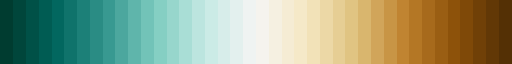

In [4]:
from matplotlib.colors import LinearSegmentedColormap
# Define the combined color list
#combined_colors = ['#ffffbf', '#feb24c','#fb6a4a','#e31a1c','#cb181d','#bd0026','#800026','#7a0177']
combined_colors = ['#543005','#8c510a','#bf812d','#dfc27d','#f6e8c3','#f5f5f5','#c7eae5','#80cdc1','#35978f','#01665e','#003c30'][::-1]
combined_colors = ['#543005','#8c510a','#bf812d','#dfc27d','#f6e8c3','#f5f5f5','#c7eae5','#80cdc1','#35978f','#01665e','#003c30'][::-1]
# Function to generate a gradient colormap with a specific number of colors
def create_gradient_colormap(n_colors, color_list=combined_colors):
    return LinearSegmentedColormap.from_list("custom_gradient", color_list, N=n_colors)

#combined_colors = ['#addd8e', '#78c679','#fe9929','#ec7014','#ef3b2c','#cb181d','#88419d','#810f7c']
#['#40004b','#762a83','#41ab5d', '#78c679','#addd8e','#fec44f','#fe9929','#ef3b2c','#cb181d','#a50f15']#['#d73027','#f46d43','#fdae61','#fee08b','#d9ef8b','#a6d96a','#66bd63','#1a9850']#['#006837', '#1a9850', '#66bd63', '#a6d96a', '#d9ef8b', '#fee08b', '#fdae61', '#f46d43', '#d73027', '#a50026']
cmap1 = create_gradient_colormap(40,combined_colors)
cmap1

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


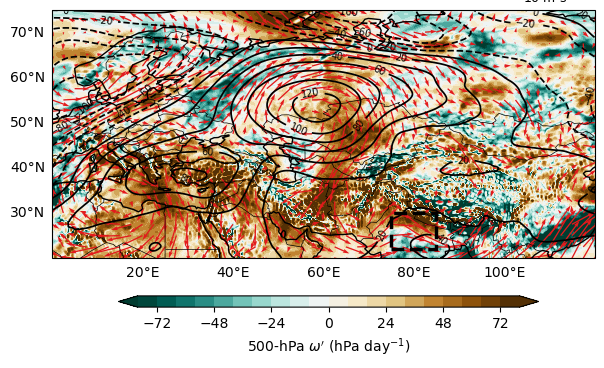

In [9]:
p = "/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/"

w = xr.open_dataset(p+"W/w.2024.era5.nc")
t = xr.open_dataset(p+"T/t.2024.era5.nc")
u = xr.open_dataset(p+"U/u.2024.era5.nc")
v = xr.open_dataset(p+"V/v.2024.era5.nc")
z_anom = xr.open_dataset("/glade/derecho/scratch/adixit/India_Heatwave/DATA/z_anom.1950-2024.nc")
t_anom = xr.open_dataset(p+"3d_fields_2024/t_anom.2024.nc")



T = slice("2024-06-10", "2024-06-20")
lat = slice(75, 20)
lon = slice(0, 120)
lev = 500
lev_wind = 850
w = w.W.sel(time=T, level=lev, latitude=lat, longitude=lon).mean("time") * 864
z = z_anom.Z500.sel(time=T,  latitude=lat, longitude=lon).mean("time") / 9.80665
u = u.U.sel(time=T, level=lev_wind, latitude=lat, longitude=lon).mean("time")
v = v.V.sel(time=T, level=lev_wind, latitude=lat, longitude=lon).mean("time")

#w, z, u, v = [x.load() for x in (w, z, u, v)]


fig, ax = plt.subplots(figsize=(7,4.5), subplot_kw={"projection": ccrs.PlateCarree()})

cf = ax.contourf(w.longitude, w.latitude, w, np.arange(-80,82,8),cmap=cmap1, extend="both")

cs = ax.contour(z.longitude, z.latitude, z, np.arange(-200,202,20),colors="k", linewidths=1.25)
ax.clabel(cs, fontsize=7)

s = 10
q = ax.quiver(u.longitude[::s], u.latitude[::s],u[::s,::s], v[::s,::s], scale=150, color='#e31a1c', label='U')




ax.quiverkey(q, 0.85, 1.05, 10,
             r'10 m s$^{-1}$', labelpos='E',
             coordinates='axes', fontproperties={'size': 9})



ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=.5)
#ax.set_extent([55,100,10,40])
cax = fig.add_axes([0.22, 0.11, 0.60, 0.025])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal")
cb.set_label(r"500-hPa $\omega'$ (hPa day$^{-1}$)")
gl = ax.gridlines(draw_labels=True, linewidth=0)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 10}
gl.ylabel_style = {"size": 10}

rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=2.5, linestyle='--')
ax.add_patch(rectangle2)
plt.savefig("Subsidence-E2-verify-era5.pdf",dpi=300,format='pdf',transparent=True)
#ax.legend(handles=legend, loc="lower left", frameon=False)
#plt.colorbar(cf, ax=ax, label=r"500-hPa $\omega'$ (hPa day$^{-1}$)")
plt.show()

In [33]:
z_anom

<xarray.Dataset> Size: 13GB
Dimensions:  (time: 13725, lat: 361, lon: 321)
Coordinates:
    level    float64 8B ...
  * time     (time) datetime64[ns] 110kB 1950-04-01 1950-04-02 ... 2024-09-30
  * lat      (lat) float64 3kB 80.0 79.75 79.5 79.25 ... -9.25 -9.5 -9.75 -10.0
  * lon      (lon) float64 3kB 40.0 40.25 40.5 40.75 ... 119.2 119.5 119.8 120.0
Data variables:
    anom     (time, lat, lon) float64 13GB ...

In [27]:
u.sel(latitude=slice(30,22),longitude=slice(75,85)).mean()

<xarray.DataArray 'U' ()> Size: 4B
array(3.242383, dtype=float32)
Coordinates:
    level    float64 8B 850.0

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


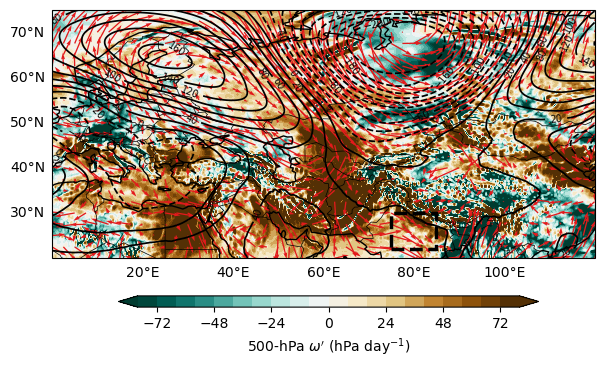

In [11]:
p = "/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/"

w = xr.open_dataset(p+"W/w.2024.era5.nc")
t = xr.open_dataset(p+"T/t.2024.era5.nc")
u = xr.open_dataset(p+"U/u.2024.era5.nc")
v = xr.open_dataset(p+"V/v.2024.era5.nc")
z_anom = xr.open_dataset("/glade/derecho/scratch/adixit/India_Heatwave/DATA/z_anom.1950-2024.nc")
t_anom = xr.open_dataset(p+"3d_fields_2024/t_anom.2024.nc")

T = slice("2024-05-25", "2024-06-01")
lat = slice(75, 20)
lon = slice(0, 120)
lev = 500
lev_wind = 850
w = w.W.sel(time=T, level=lev, latitude=lat, longitude=lon).mean("time") * 864
z = z_anom.Z500.sel(time=T,  latitude=lat, longitude=lon).mean("time") / 9.80665
u = u.U.sel(time=T, level=lev_wind, latitude=lat, longitude=lon).mean("time")
v = v.V.sel(time=T, level=lev_wind, latitude=lat, longitude=lon).mean("time")

#w, z, u, v = [x.load() for x in (w, z, u, v)]


fig, ax = plt.subplots(figsize=(7,4.5), subplot_kw={"projection": ccrs.PlateCarree()})

cf = ax.contourf(w.longitude, w.latitude, w, np.arange(-80,82,8),cmap=cmap1, extend="both")

cs = ax.contour(z.longitude, z.latitude, z, np.arange(-200,202,20),colors="k", linewidths=1.25)
ax.clabel(cs, fontsize=7)

s = 10
ax.quiver(u.longitude[::s], u.latitude[::s],u[::s,::s], v[::s,::s], scale=150, color='#e31a1c')

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=.5)
#ax.set_extent([55,100,10,40])
cax = fig.add_axes([0.22, 0.11, 0.60, 0.025])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal")
cb.set_label(r"500-hPa $\omega'$ (hPa day$^{-1}$)")
gl = ax.gridlines(draw_labels=True, linewidth=0)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 10}
gl.ylabel_style = {"size": 10}

rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=2.5, linestyle='--')
ax.add_patch(rectangle2)
plt.savefig("Subsidence-E1-verify-era5.pdf",dpi=300,format='pdf',transparent=True)
#ax.legend(handles=legend, loc="lower left", frameon=False)
#plt.colorbar(cf, ax=ax, label=r"500-hPa $\omega'$ (hPa day$^{-1}$)")
plt.show()